# Persona 3 — Agrupamiento de patrones de movilidad (Corte 3)

**Proyecto:** Taxi IA · Chapinero — Sistema inteligente para planificación de rutas y análisis de movilidad
**Curso:** SIST5036 — Inteligencia Artificial
**Enfoque:** aprendizaje automático **no supervisado** (K-Means)

### Objetivo
Identificar patrones de movilidad en la red vial de Chapinero, agrupar las vías con K-Means y analizar cómo se distribuyen los grupos en el espacio.

### Entregables de este notebook
1. Ingeniería de features por arista a partir del **dataset maestro** compartido (Persona 1) y del grafo OSM.
2. **Selección justificada de k**: codo, silueta, Davies-Bouldin, Calinski-Harabasz y estabilidad entre semillas.
3. **Evaluación** del modelo final: silueta por muestra, proyección PCA y perfiles de cada grupo.
4. Validación cruzada con la **clasificación de congestión** (Persona 2) y el **error de la regresión** (Persona 1).
5. **Visualización espacial** de las zonas y rutas agrupadas y prueba estadística de agrupamiento espacial.

> El código reutilizable vive en `backend/src/ml/agrupamiento.py`. Este notebook lo usa paso a paso y explica cada decisión.

## 1. Setup

In [1]:
from __future__ import annotations

import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.collections import LineCollection
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
BACKEND = ROOT / "backend"
sys.path.insert(0, str(BACKEND))

from src.ml import agrupamiento as ag

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 3)
plt.rcParams["figure.dpi"] = 100

## 2. Datos compartidos del equipo

| Fuente | Contenido | Uso aquí |
|--------|-----------|----------|
| `dataset_red_osm_operativo_auditado.csv.gz` (dataset maestro) | 1 741 aristas × 7 días × 24 horas con velocidad y tiempo | Perfil temporal de velocidad de cada vía |
| `dataset_osm.json` | Grafo de Chapinero (888 nodos, 1 741 aristas) con coordenadas, tipo de vía y carriles | Estructura de la red y coordenadas para el mapa |
| `dataset_clasificacion_congestion.csv` (Persona 2) | Etiqueta `baja/media/alta` por arista y hora | **Solo** para validar los grupos, nunca como feature |
| `predicciones_prueba_completas.csv.gz` (Persona 1) | Error de la regresión lineal por registro | Ver en qué grupos la regresión falla más |

In [2]:
grafo = ag.cargar_grafo_json()
nodos, aristas = ag.tablas_desde_grafo(grafo)
aristas["indice_osm"] = np.arange(len(aristas))
maestro = ag.cargar_dataset_maestro()

print(f"Nodos: {len(nodos):,} · Aristas: {len(aristas):,}")
print(f"Dataset maestro: {maestro.shape[0]:,} filas ({maestro['arista_id'].nunique():,} aristas × "
      f"{maestro['dia_semana'].nunique()} días × {maestro['hora'].nunique()} horas)")
display(maestro.head())

Nodos: 888 · Aristas: 1,741
Dataset maestro: 292,488 filas (1,741 aristas × 7 días × 24 horas)


,dia_semana,hora,velocidad_kmh,fuente_dato,arista_id
0,0,0,67.50,SIMULACION_CALIBRADA_OSM,583975820
1,0,0,40.50,SIMULACION_CALIBRADA_OSM,89615978
2,0,0,60.75,SIMULACION_CALIBRADA_OSM,856959932
3,0,0,60.75,SIMULACION_CALIBRADA_OSM,916471064
4,0,0,67.50,SIMULACION_CALIBRADA_OSM,"[1074517252, 1074517255]"


### 2.1 Hallazgo importante del dataset maestro
Antes de diseñar las features se revisa cuánta variedad real tiene el perfil de velocidad. Como la mayoría de vías vienen de la **simulación calibrada**, su perfil depende casi solo del tipo de vía:

aristas  ...  velocidad_media
tipo_via    fuente_dato                                    ...                 
otro        SIMULACION_CALIBRADA_OSM                   28  ...           33.671
primaria    SIMULACION_CALIBRADA_OSM                   27  ...           52.144
            TRANSFERENCIA_BITCARRIER_PROVISIONAL       13  ...           35.706
residencial SIMULACION_CALIBRADA_OSM                 1069  ...           31.072
secundaria  SIMULACION_CALIBRADA_OSM                  205  ...           42.402
            TRANSFERENCIA_BITCARRIER_PROVISIONAL       69  ...           26.578
terciaria   SIMULACION_CALIBRADA_OSM                  305  ...           37.145
troncal     SIMULACION_CALIBRADA_OSM                    9  ...           65.504
            TRANSFERENCIA_BITCARRIER_PROVISIONAL       16  ...           44.426

[9 rows x 3 columns]

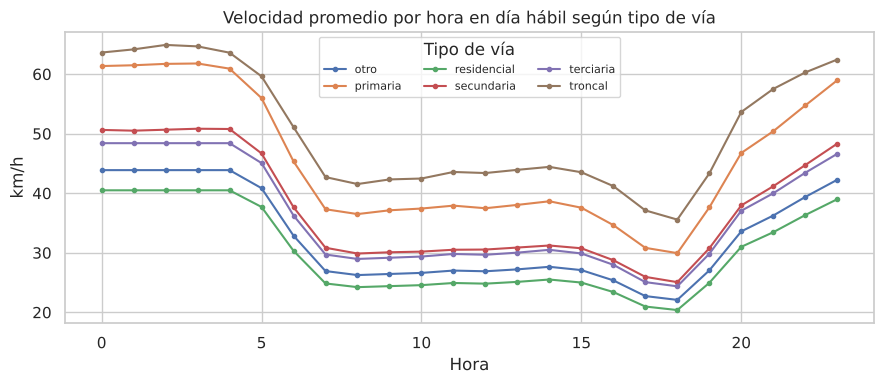

In [3]:
perfil = ag.perfil_movilidad(maestro)
resumen_tipo = (
    perfil.join(aristas.set_index("arista_id")["tipo_via"])
    .groupby(["tipo_via", "fuente_dato"])
    .agg(aristas=("velocidad_media_kmh", "size"),
         perfiles_distintos=("velocidad_media_kmh", lambda s: s.round(3).nunique()),
         velocidad_media=("velocidad_media_kmh", "mean"))
)
display(resumen_tipo)

laboral = maestro[maestro["dia_semana"] <= 4]
curva = laboral.merge(aristas[["arista_id", "tipo_via"]], on="arista_id").groupby(["tipo_via", "hora"])["velocidad_kmh"].mean().unstack(0)
ax = curva.plot(figsize=(9, 4), marker=".")
ax.set(title="Velocidad promedio por hora en día hábil según tipo de vía", xlabel="Hora", ylabel="km/h")
ax.legend(title="Tipo de vía", ncol=3, fontsize=8)
plt.tight_layout(); plt.show()

**Conclusión:** si agrupáramos solo con velocidades, K-Means devolvería prácticamente el tipo de vía (que ya conocemos). Por eso el patrón de movilidad se describe con **dos familias de features**:

* **Cómo se mueve el tráfico** (dataset maestro): velocidad media y caída de velocidad en hora pico.
* **Qué papel cumple la vía en la red** (grafo): cuántas rutas de menor tiempo pasan por ella (*betweenness*), conectividad de sus nodos, carriles y longitud.

Así un grupo no es "las residenciales", sino, por ejemplo, "las calles locales que muchas rutas usan como atajo".

## 3. Ingeniería de features

In [4]:
features = ag.construir_features_agrupamiento(maestro, nodos, aristas)
FEATS = list(ag.FEATURES_AGRUPAMIENTO)

for f in FEATS:
    print(f"- {f}: {ag.DESCRIPCION_FEATURES[f]}")
print(f"\nMatriz de entrada: {features[FEATS].shape[0]:,} aristas × {len(FEATS)} features")
display(features[FEATS].describe().T)

- velocidad_media_kmh: Velocidad promedio de la arista en las 168 horas de la semana.
- caida_hora_pico: 1 − (velocidad en la peor hora pico laboral / velocidad nocturna).
- log_intermediacion: log(1 + 1000·betweenness) ponderado por tiempo: cuántas rutas más rápidas pasan por la arista.
- carriles: Número de carriles OSM (imputado con la mediana del tipo de vía).
- log_distancia: Logaritmo de la longitud de la arista en metros.
- grado_medio: Grado promedio (entradas + salidas) de los dos nodos extremos.

Matriz de entrada: 1,741 aristas × 6 features


,count,mean,std,min,25%,50%,75%,max
velocidad_media_kmh,1741.0,33.995,7.417,17.098,31.081,31.081,31.081,68.355
caida_hora_pico,1741.0,0.436,0.017,0.318,0.435,0.435,0.435,0.600
log_intermediacion,1741.0,1.895,1.200,0.000,0.751,1.746,2.913,4.804
carriles,1741.0,2.092,0.494,1.000,2.000,2.000,2.000,5.000
log_distancia,1741.0,4.183,0.763,0.000,3.972,4.320,4.636,5.952
grado_medio,1741.0,4.345,1.169,1.500,3.500,4.000,5.000,8.000


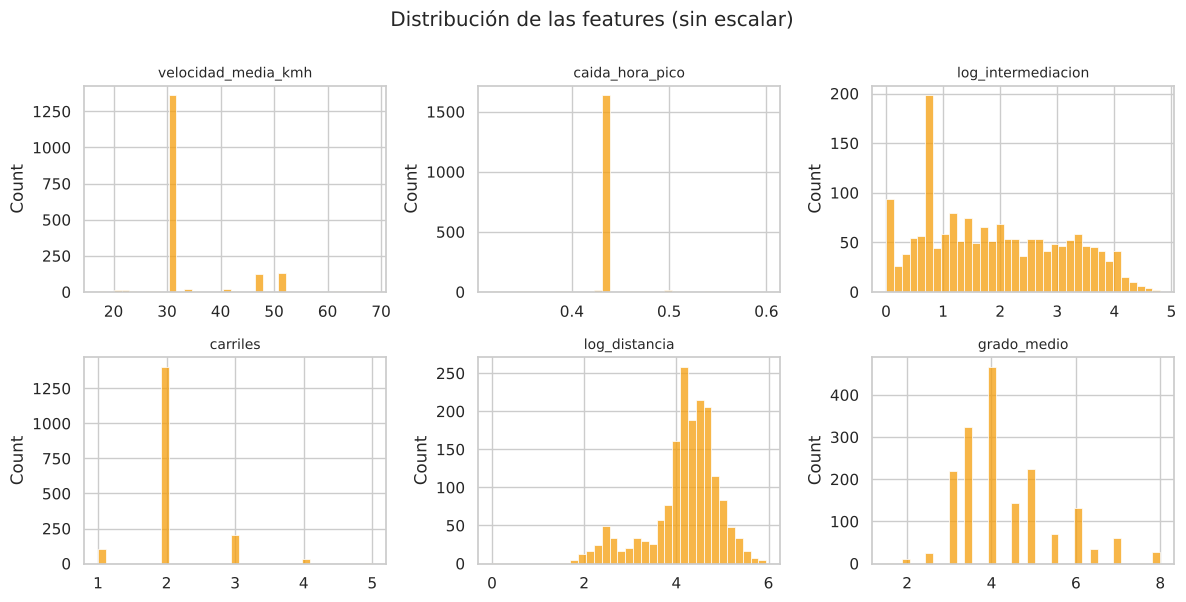

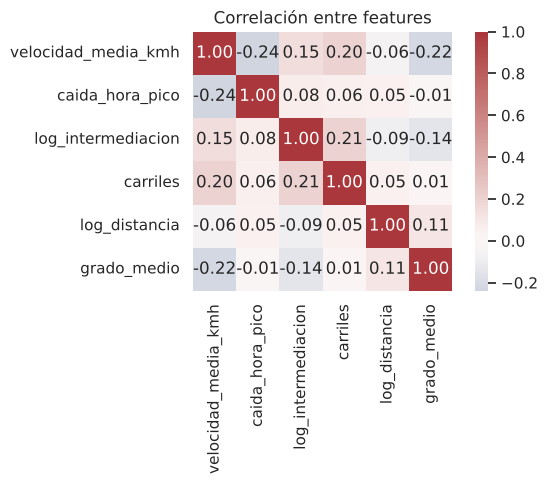

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, f in zip(axes.flat, FEATS):
    sns.histplot(features[f], bins=35, ax=ax, color="#f59e0b")
    ax.set_title(f, fontsize=10); ax.set_xlabel("")
fig.suptitle("Distribución de las features (sin escalar)", y=1.0)
plt.tight_layout(); plt.show()

plt.figure(figsize=(6.5, 5))
sns.heatmap(features[FEATS].corr(), annot=True, fmt=".2f", cmap="vlag", center=0, square=True)
plt.title("Correlación entre features"); plt.tight_layout(); plt.show()

* Las features tienen escalas muy distintas (km/h, carriles, logaritmos), así que se **estandarizan** (media 0, desviación 1) antes de K-Means; si no, la velocidad dominaría la distancia euclídea.
* Se usa el **logaritmo** de la intermediación y de la longitud porque ambas son muy asimétricas (pocas vías concentran casi todo el flujo).
* Ninguna pareja está casi perfectamente correlacionada, así que no se repite información.

## 4. Selección del número de grupos *k*

Se entrena K-Means para k = 2 … 10 y se calculan cinco criterios:

| Criterio | Qué mide | Mejor |
|----------|----------|-------|
| Inercia (codo) | Suma de distancias al centroide | Punto donde deja de bajar rápido |
| Silueta | Qué tan separado está cada punto de otros grupos | ↑ (máx 1) |
| Davies-Bouldin | Parecido entre grupos | ↓ |
| Calinski-Harabasz | Dispersión entre grupos / dentro de grupos | ↑ |
| Estabilidad (ARI) | Si con otra semilla salen los mismos grupos | ↑ (máx 1) |

In [6]:
X = features[FEATS]
tabla_k = ag.evaluar_rango_k(X)
display(tabla_k.style.format(precision=3).highlight_max(subset=["silueta", "calinski_harabasz", "estabilidad_ari", "codo_kneedle"], color="#fde68a").highlight_min(subset=["davies_bouldin"], color="#fde68a"))

,k,inercia,silueta,davies_bouldin,calinski_harabasz,estabilidad_ari,grupo_minimo_pct,codo_kneedle
0,2,8631.206,0.322,1.504,365.641,0.978,16.600,0.000
1,3,7391.845,0.200,1.621,359.053,0.981,15.968,0.107
2,4,6278.739,0.227,1.344,384.298,0.983,2.872,0.190
3,5,5447.527,0.251,1.233,398.224,0.833,2.872,0.220
4,6,4745.275,0.266,1.128,416.870,0.992,2.872,0.226
5,7,4232.652,0.277,1.109,424.239,0.854,2.585,0.197
6,8,3780.715,0.291,1.039,436.463,0.853,0.862,0.156
7,9,3466.554,0.302,1.039,435.894,0.784,0.862,0.090
8,10,3280.217,0.269,1.080,420.161,0.739,0.862,0.000


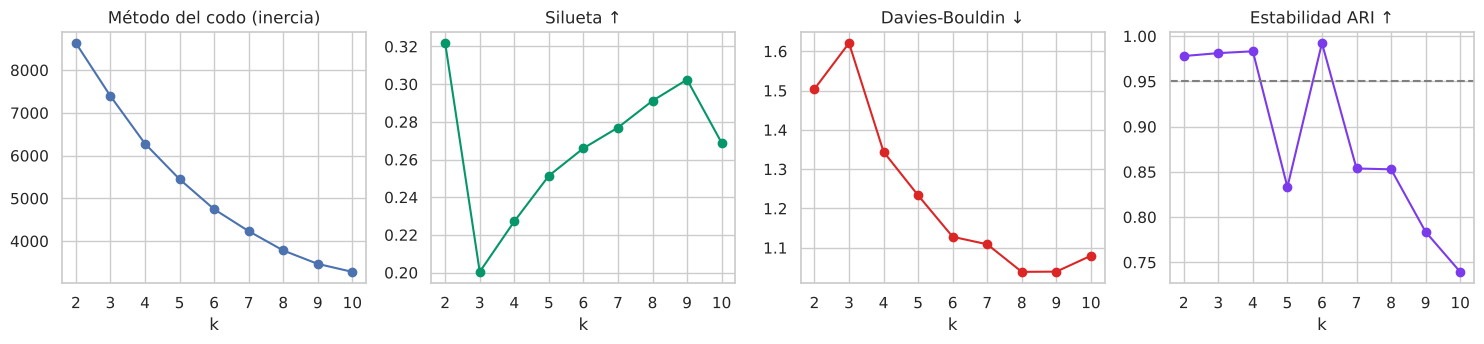

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
k = tabla_k["k"]
axes[0].plot(k, tabla_k["inercia"], "o-"); axes[0].set_title("Método del codo (inercia)")
axes[1].plot(k, tabla_k["silueta"], "o-", color="#059669"); axes[1].set_title("Silueta ↑")
axes[2].plot(k, tabla_k["davies_bouldin"], "o-", color="#dc2626"); axes[2].set_title("Davies-Bouldin ↓")
axes[3].plot(k, tabla_k["estabilidad_ari"], "o-", color="#7c3aed"); axes[3].axhline(ag.UMBRAL_ESTABILIDAD_ARI, ls="--", c="gray")
axes[3].set_title("Estabilidad ARI ↑")
for ax in axes: ax.set_xlabel("k"); ax.set_xticks(k)
plt.tight_layout(); plt.show()

### Regla de decisión (implementada en `seleccionar_k`)
1. **k ≥ 3.** k = 2 suele ganar en silueta, pero solo parte la red en "avenidas rápidas" vs "todo lo demás"; no aporta patrones nuevos.
2. **Estabilidad ARI ≥ 0.95.** Si con otra semilla K-Means arma grupos distintos, los grupos no son confiables para el informe ni para la app.
3. Entre los k estables, gana la mejor **suma de rangos** en silueta, Davies-Bouldin, Calinski-Harabasz y codo; si hay empate, el k más pequeño (más fácil de interpretar).

In [8]:
K, justificacion = ag.seleccionar_k(tabla_k)
print(f"k elegido = {K}\n")
for linea in justificacion:
    print("•", linea)

k elegido = 6

• k = 2 tiene la silueta más alta (0.322) pero solo separa las vías arteriales rápidas del resto; no describe patrones de movilidad útiles.
• Se exige estabilidad ARI ≥ 0.95 entre 10 inicializaciones; quedan fuera k = 5, 7, 8, 9, 10.
• Entre los k estables, k = 6 obtiene la mejor combinación de silueta (0.266), Davies-Bouldin (1.128), Calinski-Harabasz (417) y codo de la inercia.
• Con k = 6 el grupo más pequeño reúne el 2.9 % de las aristas y la partición se repite con ARI 0.992.


## 5. Modelo final y evaluación

In [9]:
res = ag.entrenar_agrupamiento(features, k=K)
datos = res.datos
nombres = {c: v["nombre"] for c, v in res.nombres.items()}
datos["grupo"] = datos["cluster"].map(lambda c: f"{c} · {nombres[c]}")

print("Métricas del modelo final:")
for m, v in res.metricas.items():
    print(f"  {m:<20} {v:,.4f}")

tam = datos["grupo"].value_counts().sort_index()
display(pd.DataFrame({"aristas": tam, "%": (100 * tam / len(datos)).round(1)}))

Métricas del modelo final:
  silueta              0.2660
  davies_bouldin       1.1279
  calinski_harabasz    416.8703
  inercia              4,745.2747
  estabilidad_ari      0.9923
  varianza_pca_2d      0.4483


,aristas,%
grupo,,
0 · Corredores rápidos,246,14.1
1 · Tramos cortos de intersección,194,11.1
2 · Vías residenciales internas,551,31.6
3 · Vías colectoras de paso,405,23.3
4 · Malla local densa,295,16.9
5 · Corredores críticos en hora pico,50,2.9


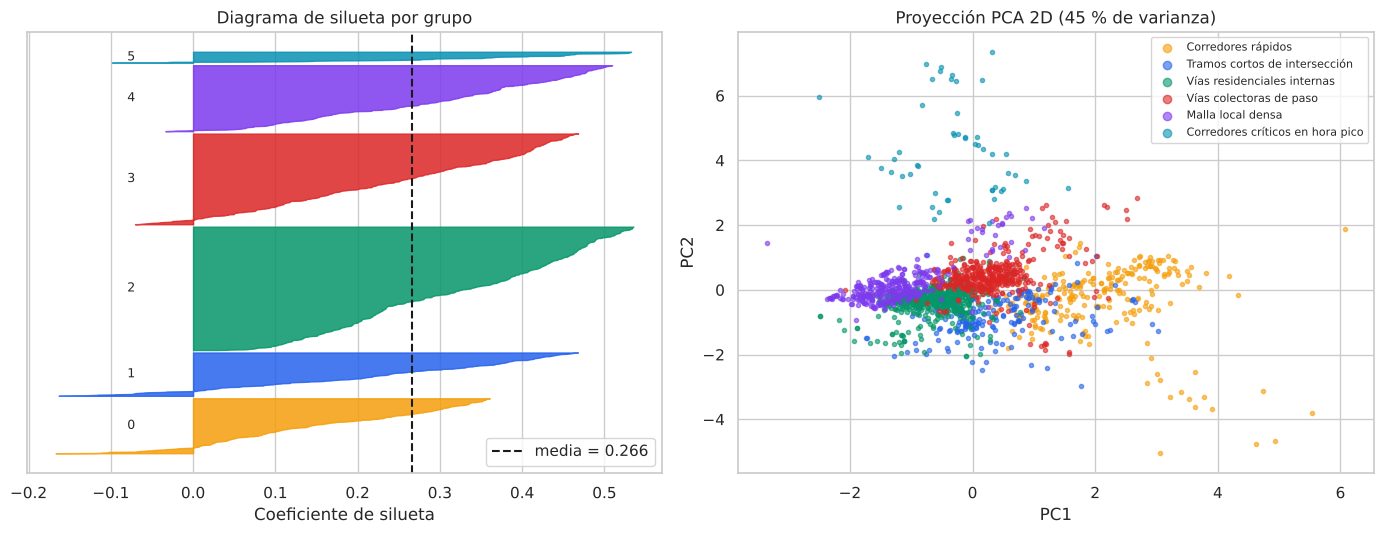

In [10]:
PALETA = ["#f59e0b", "#2563eb", "#059669", "#dc2626", "#7c3aed", "#0891b2", "#db2777", "#65a30d", "#78716c", "#ea580c"]
colores = {c: PALETA[c % len(PALETA)] for c in range(K)}

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5.5))
# Diagrama de silueta
y = 10
for c in range(K):
    s = np.sort(datos.loc[datos["cluster"] == c, "silueta"].to_numpy())
    a1.fill_betweenx(np.arange(y, y + len(s)), 0, s, color=colores[c], alpha=.85)
    a1.text(-0.08, y + len(s) / 2, str(c), va="center", fontsize=9)
    y += len(s) + 10
a1.axvline(res.metricas["silueta"], color="k", ls="--", label=f"media = {res.metricas['silueta']:.3f}")
a1.set(title="Diagrama de silueta por grupo", xlabel="Coeficiente de silueta", yticks=[]); a1.legend()
# Proyección PCA
for c in range(K):
    sub = datos[datos["cluster"] == c]
    a2.scatter(sub["pca_1"], sub["pca_2"], s=9, alpha=.6, color=colores[c], label=nombres[c])
a2.set(title=f"Proyección PCA 2D ({100 * res.metricas['varianza_pca_2d']:.0f} % de varianza)", xlabel="PC1", ylabel="PC2")
a2.legend(fontsize=8, markerscale=2)
plt.tight_layout(); plt.show()

**Lectura:**
* La silueta media es moderada: hay grupos bien definidos (los corredores, la malla densa) y otros que se tocan en la frontera, algo normal en una red vial donde las vías cambian de forma gradual.
* Las siluetas negativas son pocas y pequeñas (aristas en la frontera entre dos grupos); la gran mayoría está más cerca de su propio grupo que de cualquier otro.
* En la proyección PCA los corredores (rápidos y críticos) se separan claramente del bloque de vías locales, que K-Means divide según su papel en la red.

## 6. Perfil de cada grupo

,velocidad_media_kmh,vel_pico_pm_kmh,vel_noche_kmh,caida_hora_pico,intermediacion,grado_medio,carriles,distancia_m
Corredores rápidos,50.170,36.395,63.751,0.429,0.019,3.740,2.431,87.218
Tramos cortos de intersección,33.232,23.981,42.445,0.435,0.011,3.845,1.866,15.419
Vías residenciales internas,31.345,22.617,40.026,0.435,0.002,3.917,1.920,100.800
Vías colectoras de paso,31.152,22.542,39.780,0.433,0.026,4.128,2.106,82.091
Malla local densa,31.139,22.475,39.768,0.435,0.004,6.364,2.166,84.616
Corredores críticos en hora pico,26.468,17.786,36.514,0.511,0.037,3.830,2.640,105.055


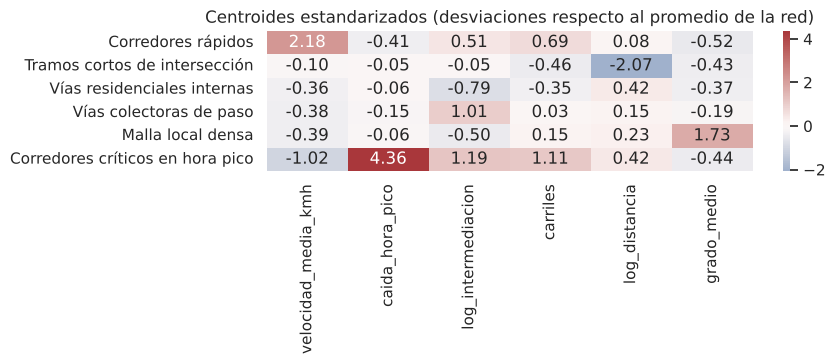

In [11]:
cols_perfil = ["velocidad_media_kmh", "vel_pico_pm_kmh", "vel_noche_kmh", "caida_hora_pico", "intermediacion", "grado_medio", "carriles", "distancia_m"]
tabla_perfil = res.perfiles[cols_perfil].copy()
tabla_perfil.index = [nombres[c] for c in tabla_perfil.index]
display(tabla_perfil.style.format(precision=3).background_gradient(cmap="YlOrBr", axis=0))

centros = res.pipeline.named_steps["kmeans"].cluster_centers_
orden = res.datos.groupby(res.pipeline.named_steps["kmeans"].labels_)["cluster"].first().sort_values()
z = pd.DataFrame(centros[orden.index], columns=FEATS, index=[nombres[c] for c in orden.values])
plt.figure(figsize=(9, 3.8))
sns.heatmap(z, annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("Centroides estandarizados (desviaciones respecto al promedio de la red)")
plt.tight_layout(); plt.show()

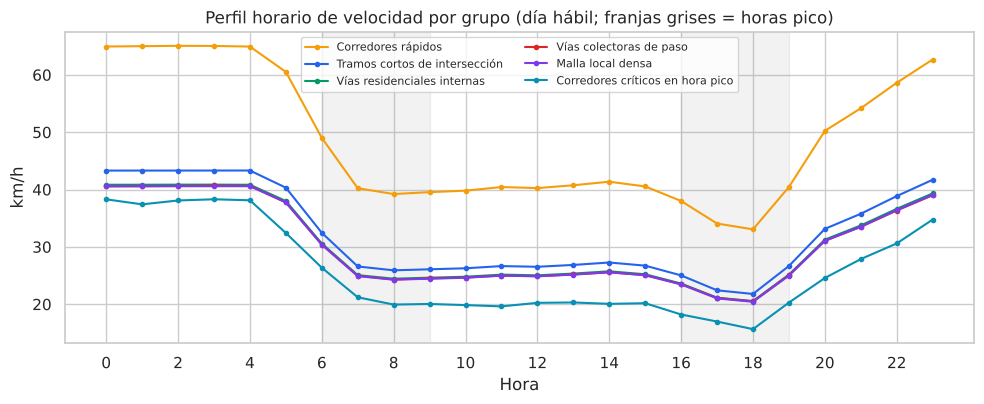

In [12]:
laboral_c = laboral.merge(datos[["cluster"]], left_on="arista_id", right_index=True)
curvas = laboral_c.groupby(["cluster", "hora"])["velocidad_kmh"].mean().unstack(0)
fig, ax = plt.subplots(figsize=(10, 4.2))
for c in curvas.columns:
    ax.plot(curvas.index, curvas[c], marker=".", color=colores[c], label=nombres[c])
ax.axvspan(6, 9, color="gray", alpha=.1); ax.axvspan(16, 19, color="gray", alpha=.1)
ax.set(title="Perfil horario de velocidad por grupo (día hábil; franjas grises = horas pico)", xlabel="Hora", ylabel="km/h", xticks=range(0, 24, 2))
ax.legend(fontsize=8, ncol=2); plt.tight_layout(); plt.show()

In [13]:
for g in sorted(res.nombres):
    info, p = res.nombres[g], res.perfiles.loc[g]
    n = int((datos["cluster"] == g).sum())
    print(f"[{g}] {info['nombre']} — {n} aristas")
    print(f"    {info['descripcion']}")
    print(f"    velocidad media {p['velocidad_media_kmh']:.1f} km/h · pico PM {p['vel_pico_pm_kmh']:.1f} km/h · "
          f"caída en pico {100 * p['caida_hora_pico']:.0f} % · grado {p['grado_medio']:.1f} · longitud {p['distancia_m']:.0f} m\n")

[0] Corredores rápidos — 246 aristas
    Avenidas y troncales con las velocidades más altas durante todo el día.
    velocidad media 50.2 km/h · pico PM 36.4 km/h · caída en pico 43 % · grado 3.7 · longitud 87 m

[1] Tramos cortos de intersección — 194 aristas
    Segmentos muy cortos que conectan cruces, glorietas y accesos.
    velocidad media 33.2 km/h · pico PM 24.0 km/h · caída en pico 44 % · grado 3.8 · longitud 15 m

[2] Vías residenciales internas — 551 aristas
    Calles de barrio que casi ninguna ruta usa como paso.
    velocidad media 31.3 km/h · pico PM 22.6 km/h · caída en pico 43 % · grado 3.9 · longitud 101 m

[3] Vías colectoras de paso — 405 aristas
    Calles locales que muchas rutas usan para llegar a los corredores.
    velocidad media 31.2 km/h · pico PM 22.5 km/h · caída en pico 43 % · grado 4.1 · longitud 82 m

[4] Malla local densa — 295 aristas
    Vías locales entre intersecciones muy conectadas, con poco tráfico de paso.
    velocidad media 31.1 km/h · pico P

## 7. Validación externa con el trabajo del equipo
K-Means no vio ni las etiquetas de congestión ni los errores de la regresión. Si los grupos tienen sentido, esas variables deberían comportarse distinto entre grupos.

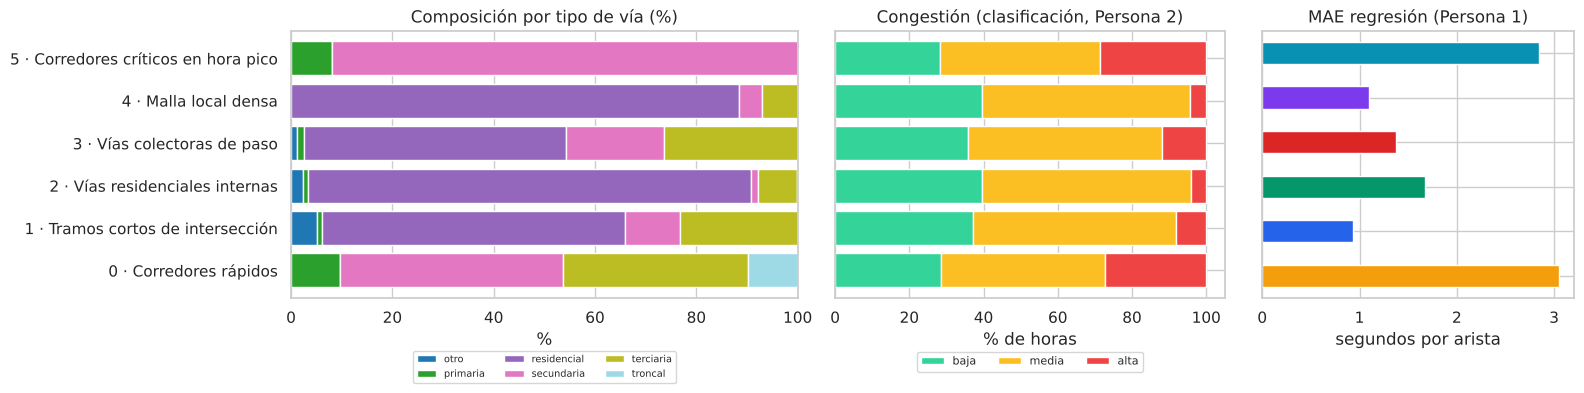

,baja,media,alta,MAE_regresion_s
Corredores rápidos,28.6,44.1,27.3,3.05
Tramos cortos de intersección,37.2,54.5,8.2,0.93
Vías residenciales internas,39.6,56.3,4.1,1.67
Vías colectoras de paso,35.7,52.3,11.9,1.37
Malla local densa,39.6,56.1,4.3,1.09
Corredores críticos en hora pico,28.4,43.1,28.5,2.85


In [14]:
tipos = pd.crosstab(datos["grupo"], datos["tipo_via"], normalize="index") * 100
congestion = ag.cruce_clasificacion(datos)
regresion = ag.cruce_regresion(datos)

fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(16, 4.2), gridspec_kw={"width_ratios": [1.3, 1, .8]})
tipos.plot.barh(stacked=True, ax=a1, colormap="tab20", width=.8)
a1.set(title="Composición por tipo de vía (%)", xlabel="%", ylabel=""); a1.legend(fontsize=7, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.18))

cong = pd.DataFrame(congestion).T.reindex(columns=["baja", "media", "alta"]) * 100
cong.index = [nombres[c] for c in cong.index]
cong.plot.barh(stacked=True, ax=a2, color=["#34d399", "#fbbf24", "#ef4444"], width=.8)
a2.set(title="Congestión (clasificación, Persona 2)", xlabel="% de horas"); a2.legend(fontsize=8, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.18))

reg = pd.Series({nombres[c]: v["mae_s"] for c, v in regresion.items()})
reg.plot.barh(ax=a3, color=[colores[c] for c in regresion]); a3.set(title="MAE regresión (Persona 1)", xlabel="segundos por arista")
for ax in (a2, a3): ax.set_yticklabels([] if ax is not a1 else ax.get_yticklabels())
plt.tight_layout(); plt.show()

display(cong.round(1).assign(MAE_regresion_s=reg.round(2)))

**Lectura:**
* Los **corredores** (rápidos y críticos) concentran las horas de congestión **alta**, mientras que la malla local y las vías residenciales casi nunca llegan a alta: los grupos coinciden con lo que aprendió el clasificador sin haber usado su etiqueta.
* La **regresión lineal** comete más error (en segundos) en los corredores; ahí conviene que el equipo revise features específicas para mejorar la predicción de tiempos.

## 8. Distribución espacial de los grupos

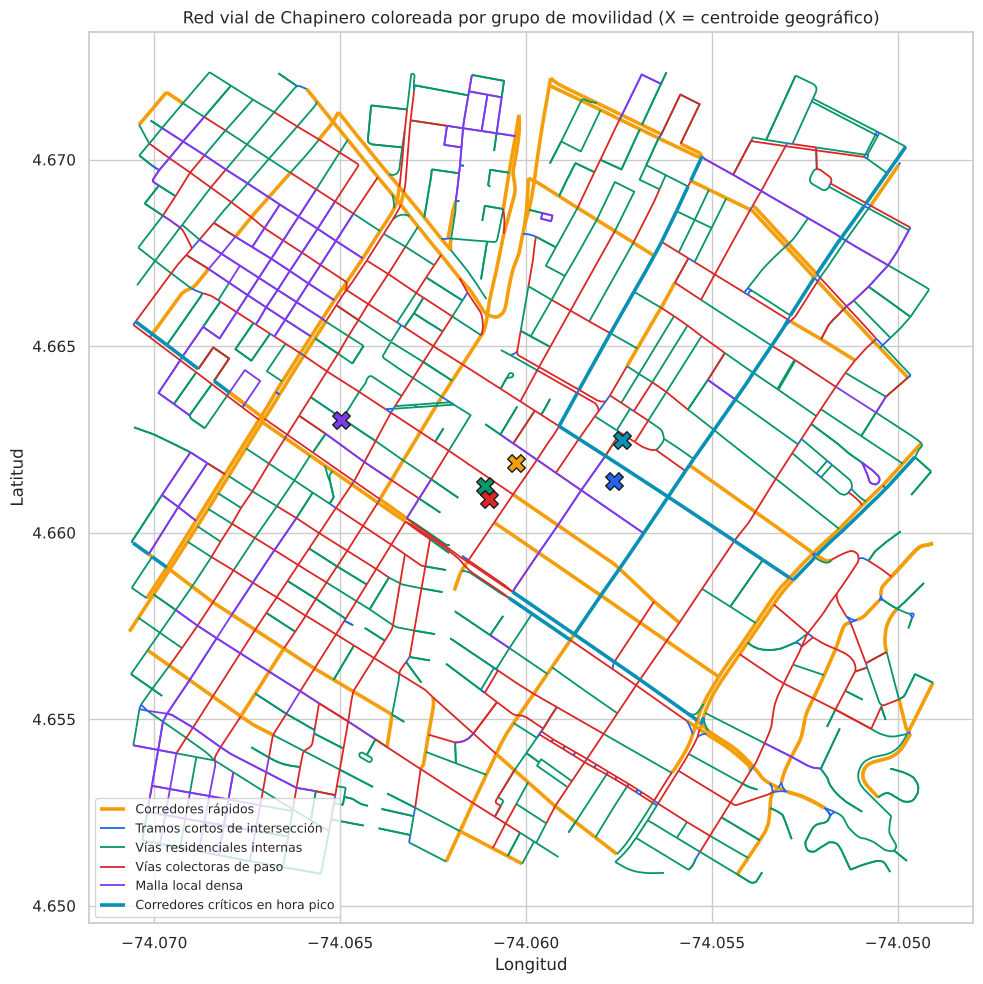

In [15]:
def segmentos(df):
    out = []
    for fila in df.itertuples():
        geom = fila.geometria
        if isinstance(geom, list) and len(geom) >= 2:
            out.append([(x, y) for x, y in geom])
        else:
            out.append([(fila.lon_origen, fila.lat_origen), (fila.lon_destino, fila.lat_destino)])
    return out

aspecto = 1 / np.cos(np.radians(datos["latitud"].mean()))
fig, ax = plt.subplots(figsize=(10, 10))
for c in range(K):
    sub = datos[datos["cluster"] == c]
    ancho = 2.6 if res.perfiles.loc[c, "velocidad_media_kmh"] > 40 or res.nombres[c]["nombre"].startswith("Corredores críticos") else 1.3
    ax.add_collection(LineCollection(segmentos(sub), colors=colores[c], linewidths=ancho, label=nombres[c]))
espacial = ag.distribucion_espacial(datos)
for e in espacial:
    ax.scatter(e["centroide"]["longitud"], e["centroide"]["latitud"], s=160, marker="X", color=colores[e["cluster"]], edgecolor="k", zorder=5)
ax.autoscale(); ax.set_aspect(aspecto)
ax.set(title="Red vial de Chapinero coloreada por grupo de movilidad (X = centroide geográfico)", xlabel="Longitud", ylabel="Latitud")
ax.legend(loc="lower left", fontsize=9)
plt.tight_layout(); plt.show()

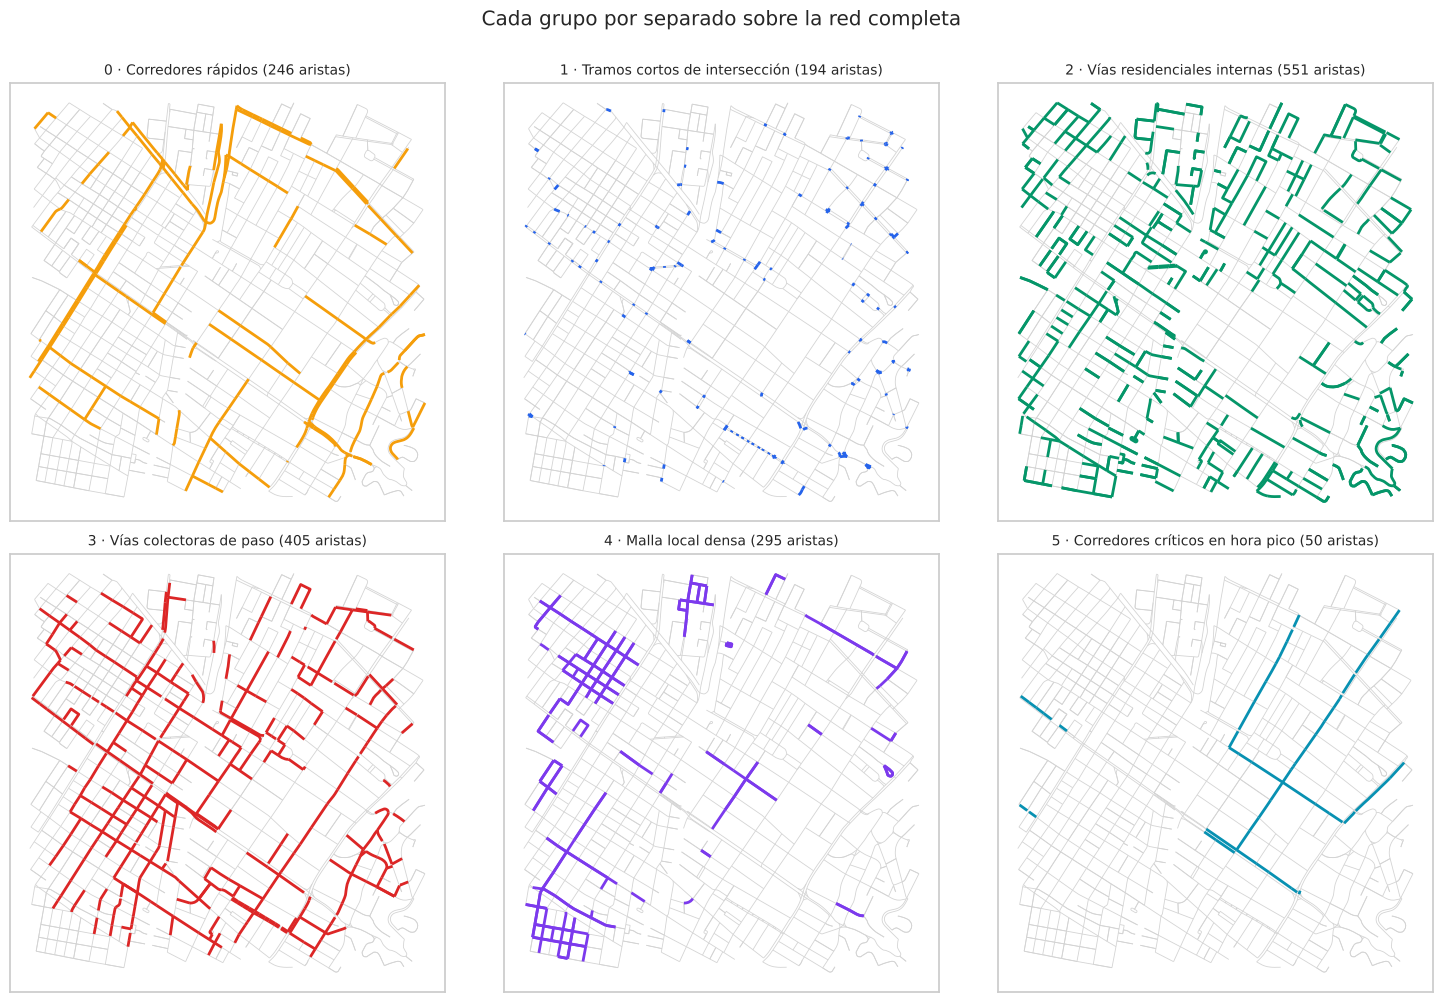

In [16]:
filas = int(np.ceil(K / 3))
fig, axes = plt.subplots(filas, 3, figsize=(15, 5 * filas))
todas = segmentos(datos)
for c, ax in zip(range(K), axes.flat):
    ax.add_collection(LineCollection(todas, colors="#d4d4d4", linewidths=.6))
    ax.add_collection(LineCollection(segmentos(datos[datos["cluster"] == c]), colors=colores[c], linewidths=2))
    ax.autoscale(); ax.set_aspect(aspecto); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{c} · {nombres[c]} ({(datos['cluster'] == c).sum()} aristas)", fontsize=10)
for ax in list(axes.flat)[K:]:
    ax.axis("off")
plt.suptitle("Cada grupo por separado sobre la red completa", y=1.0); plt.tight_layout(); plt.show()

In [17]:
tabla_esp = pd.DataFrame([
    {"grupo": nombres[e["cluster"]],
     "km de vía": round(e["longitud_total_km"], 2),
     "dist. centroide al centro (m)": round(e["distancia_al_centro_zona_m"]),
     "dispersión media (m)": round(e["dispersion_media_m"]),
     "vías principales": ", ".join(v["nombre"] for v in e["vias_principales"][:3])}
    for e in espacial
])
display(tabla_esp)

h = ag.homofilia_espacial(datos)
print("Prueba de agrupamiento espacial (aristas que comparten un nodo):")
print(f"  Pares de aristas vecinas analizados: {h['pares']:,}")
print(f"  Vecinas en el mismo grupo (observado): {100 * h['observada']:.1f} %")
print(f"  Esperado si los grupos fueran al azar: {100 * h['esperada_azar']:.1f} %")
print(f"  Razón observado/azar: {h['razon']:.2f}×  ·  p-valor (permutaciones): {h['p_valor']:.4f}")

,grupo,km de vía,dist. centroide al centro (m),dispersión media (m),vías principales
0,Corredores rápidos,21.46,100,906,"Avenida Carrera 24, Avenida Carrera 7, Avenida Calle 80"
1,Tramos cortos de intersección,2.99,387,933,"Calle 70, Calle 72, Carrera 10"
2,Vías residenciales internas,55.54,39,942,"Calle 70A, Calle 71, Carrera 22"
3,Vías colectoras de paso,33.25,80,799,"Avenida Calle 72, Carrera 9, Calle 74"
4,Malla local densa,24.96,456,842,"Carrera 21, Calle 75, Calle 77"
5,Corredores críticos en hora pico,5.25,422,656,"Avenida Carrera 11, Avenida Calle 72, Avenida Carrera 15"


Prueba de agrupamiento espacial (aristas que comparten un nodo):
  Pares de aristas vecinas analizados: 5,457
  Vecinas en el mismo grupo (observado): 47.5 %
  Esperado si los grupos fueran al azar: 21.5 %
  Razón observado/azar: 2.21×  ·  p-valor (permutaciones): 0.0033


**Lectura espacial:**
* Los grupos **no** están repartidos al azar: dos aristas vecinas caen en el mismo grupo más del doble de veces de lo esperado por azar (p < 0.01). Los patrones forman **corredores y zonas continuas**.
* Los **corredores rápidos** siguen los ejes arteriales (Av. Carrera 7, Av. Carrera 24, Av. Calle 80) y los **corredores críticos** se concentran en tramos como la Av. Carrera 11, la Av. Carrera 15 y la Av. Calle 72: los puntos que más conviene evitar en hora pico.
* La **malla local densa** y las **vías residenciales internas** ocupan el interior de los barrios, y las **vías colectoras** son las calles que conectan esos barrios con los corredores; por definición (alta intermediación) son las que más usan las rutas de menor tiempo que calculan los algoritmos de búsqueda.

## 9. Conclusiones
1. Con 6 features (velocidad, caída en hora pico, intermediación, conectividad, carriles y longitud), K-Means encuentra **6 patrones de movilidad** estables (ARI ≈ 0.99 entre semillas).
2. La elección de *k* no depende de una sola métrica: se descartó k = 2 (trivial) y los k inestables, y se eligió el mejor compromiso entre codo, silueta, Davies-Bouldin y Calinski-Harabasz.
3. Los grupos coinciden con la congestión que predice el clasificador y con los errores de la regresión, **sin haber usado esas variables**, lo que respalda su validez.
4. Espacialmente se forman corredores continuos; esto sirve en la app para explicar por qué una ruta evita ciertos ejes en hora pico.

### Limitaciones
* El perfil horario del dataset maestro es en su mayoría **simulado** (solo ~6 % de aristas tiene transferencia Bitcarrier). Con datos reales los grupos de vías locales podrían separarse más por velocidad.
* La silueta (~0.27) indica grupos con fronteras suaves; es esperable en una red continua, pero no deben leerse como categorías rígidas.
* La intermediación se calcula con tiempos base, sin cierres ni tráfico dinámico.

## 10. Exportar artefactos para la API y el dashboard

In [18]:
res_final, payload = ag.ejecutar_pipeline_completo(k=K)
destino_front = ROOT / "frontend" / "public" / "datos" / "ml_agrupamiento_resumen.json"
import json
destino_front.write_text(json.dumps(payload, ensure_ascii=False, separators=(",", ":")), encoding="utf-8")
print("Artefactos guardados en", ag.directorio_agrupamiento().relative_to(ROOT))
for p in sorted(ag.directorio_agrupamiento().iterdir()):
    print("  -", p.name)
print("Respaldo del dashboard:", destino_front.relative_to(ROOT))

Artefactos guardados en backend/datos/ml/agrupamiento
  - asignaciones_clusters.csv
  - evaluacion_k.csv
  - metricas_agrupamiento.json
  - modelo_kmeans_movilidad.joblib
Respaldo del dashboard: frontend/public/datos/ml_agrupamiento_resumen.json
